<a href="https://colab.research.google.com/github/maxiangt/MSSP6070/blob/main/Assignments/MSSP607_As2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

sns.set_theme(style='whitegrid', context='notebook')

url = "https://raw.githubusercontent.com/maxiangt/MSSP6070/main/Assignments/InternetSales.csv"

try:
    df = pd.read_csv(url, encoding='latin-1', low_memory=False)
    data_source = "GitHub"
except Exception as e:
    print("GitHub loading failed:", e)
    from google.colab import files
    uploaded = files.upload()

    if not uploaded:
        raise ValueError("No CSV file was uploaded.")

    filename = next(iter(uploaded))
    df = pd.read_csv(filename, encoding='latin-1', low_memory=False)
    data_source = f"Uploaded file: {filename}"

print(f"Data loaded successfully from {data_source}.")
print("Dataset shape:", df.shape)
print("Number of order lines:", len(df))
print("Number of unique customers:", df['CustomerKey'].nunique())
print("Number of unique orders:", df['SalesOrderNumber'].nunique())

display(df.head())

Data loaded successfully from GitHub.
Dataset shape: (60398, 60)
Number of order lines: 60398
Number of unique customers: 18484
Number of unique orders: 27659


,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,LastName,NameStyle,BirthDate,MaritalStatus,Suffix,Gender,EmailAddress,YearlyIncome,TotalChildren,NumberChildrenAtHome,EnglishEducation,SpanishEducation,FrenchEducation,EnglishOccupation,SpanishOccupation,FrenchOccupation,HouseOwnerFlag,NumberCarsOwned,AddressLine1,AddressLine2,Phone,DateFirstPurchase,CommuteDistance,ProductKey,EnglishProductName,OrderDateKey,DueDateKey,ShipDateKey,CustomerKey.1,PromotionKey,CurrencyKey,SalesTerritoryKey,SalesOrderNumber,SalesOrderLineNumber,RevisionNumber,OrderQuantity,UnitPrice,ExtendedAmount,UnitPriceDiscountPct,DiscountAmount,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,False,10/6/1971,M,NaN,M,jon24@adventure-works.com,90000,2,0,Bachelors,Licenciatura,Bac + 4,Professional,Profesional,Cadre,1,0,3761 N. 14th St,NaN,1 (11) 500 555-0162,1/19/2011,1-2 Miles,344,"Mountain-100 Silver, 38",20110119,20110131,20110126,11000,1,6,9,SO43793,1,1,1,3399.99,3399.99,0,0,1912.1544,1912.1544,3399.99,271.9992,84.9998,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,False,10/6/1971,M,NaN,M,jon24@adventure-works.com,90000,2,0,Bachelors,Licenciatura,Bac + 4,Professional,Profesional,Cadre,1,0,3761 N. 14th St,NaN,1 (11) 500 555-0162,1/19/2011,1-2 Miles,353,"Mountain-200 Silver, 38",20130118,20130130,20130125,11000,2,6,9,SO51522,1,1,1,2319.99,2319.99,0,0,1265.6195,1265.6195,2319.99,185.5992,57.9998,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,False,10/6/1971,M,NaN,M,jon24@adventure-works.com,90000,2,0,Bachelors,Licenciatura,Bac + 4,Professional,Profesional,Cadre,1,0,3761 N. 14th St,NaN,1 (11) 500 555-0162,1/19/2011,1-2 Miles,485,Fender Set - Mountain,20130118,20130130,20130125,11000,1,6,9,SO51522,2,1,1,21.98,21.98,0,0,8.2205,8.2205,21.98,1.7584,0.5495,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,False,10/6/1971,M,NaN,M,jon24@adventure-works.com,90000,2,0,Bachelors,Licenciatura,Bac + 4,Professional,Profesional,Cadre,1,0,3761 N. 14th St,NaN,1 (11) 500 555-0162,1/19/2011,1-2 Miles,573,"Touring-1000 Blue, 46",20130503,20130515,20130510,11000,1,6,9,SO57418,1,1,1,2384.07,2384.07,0,0,1481.9379,1481.9379,2384.07,190.7256,59.6018,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,False,10/6/1971,M,NaN,M,jon24@adventure-works.com,90000,2,0,Bachelors,Licenciatura,Bac + 4,Professional,Profesional,Cadre,1,0,3761 N. 14th St,NaN,1 (11) 500 555-0162,1/19/2011,1-2 Miles,541,Touring Tire,20130503,20130515,20130510,11000,1,6,9,SO57418,2,1,1,28.99,28.99,0,0,10.8423,10.8423,28.99,2.3192,0.7248,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


In [ ]:
# ==========================================
# Data Cleaning and Variable Preparation
# ==========================================

# 1. Convert date columns
date_cols = [
    'OrderDate',
    'DueDate',
    'ShipDate',
    'DateFirstPurchase',
    'BirthDate'
]

for c in date_cols:
    if c in df.columns:
        df[c] = pd.to_datetime(df[c], errors='coerce')


# 2. Convert numeric columns
numeric_cols = [
    'YearlyIncome',
    'SalesAmount',
    'UnitPrice',
    'OrderQuantity',
    'HouseOwnerFlag',
    'TotalProductCost',
    'ProductStandardCost',
    'UnitPriceDiscountPct'
]

for c in numeric_cols:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors='coerce')


# 3. Extract order year
df['OrderYear'] = pd.to_datetime(
    df['OrderDateKey'].astype('string'),
    format='%Y%m%d',
    errors='coerce'
).dt.year

# Use OrderDate as a fallback
if 'OrderDate' in df.columns:
    df['OrderYear'] = df['OrderYear'].fillna(
        df['OrderDate'].dt.year
    )


# 4. Clean country region
df['CountryRegion'] = (
    df['EnglishCountryRegionName']
    .astype('string')
    .str.strip()
)


# 5. Clean gender
df['Gender'] = (
    df['Gender']
    .astype('string')
    .str.strip()
)

# Encode gender: Male = 1, Female = 0
df['GenderNumeric'] = df['Gender'].map({
    'M': 1,
    'F': 0
})


# 6. Classify products
def classify_product(name):

    if pd.isna(name):
        return 'Unmapped'


    s = str(name).lower().strip()

    # Bikes
    if s.startswith(('mountain-', 'road-', 'touring-')):
        return 'Bikes'

    # Clothing
    if any(k in s for k in [
        'jersey',
        'shorts',
        'vest',
        'gloves',
        'socks',
        'cap'
    ]):
        return 'Clothing'

       # Accessories
    if any(k in s for k in [
        'tire',
        'tube',
        'bottle',
        'cage',
        'helmet',
        'fender',
        'patch',
        'hydration',
        'bike stand',
        'hitch rack',
        'bike wash'
    ]):
        return 'Accessories'

    # Anything else is flagged for review
    return 'Unmapped'


df['ProductCategory'] = (
    df['EnglishProductName'].apply(classify_product)
)


# 7. Audit product classification
product_audit = (
    df[['EnglishProductName', 'ProductCategory']]
    .drop_duplicates()
    .sort_values(['ProductCategory', 'EnglishProductName'])
)

display(product_audit)

print("\nProduct category counts:")
print(df['ProductCategory'].value_counts(dropna=False))

print(
    "\nUnmapped product records:",
    (df['ProductCategory'] == 'Unmapped').sum()
)

print("\nUnmapped product names:")

display(
    df.loc[
        df['ProductCategory'] == 'Unmapped',
        ['EnglishProductName']
    ].drop_duplicates()
)


# 8. Check missing values
print("\nMissing values in key columns:")

print(
    df[
        [
            'OrderYear',
            'CountryRegion',
            'SalesAmount',
            'YearlyIncome',
            'Gender',
            'HouseOwnerFlag',
            'ProductCategory'
        ]
    ].isna().sum()
)


# 9. Display product classification examples
print("\nProduct name and category examples:")

display(
    df[
        ['EnglishProductName', 'ProductCategory']
    ].drop_duplicates().head(40)
)

,EnglishProductName,ProductCategory
95,All-Purpose Bike Stand,Accessories
158,Bike Wash - Dissolver,Accessories
2,Fender Set - Mountain,Accessories
40,HL Mountain Tire,Accessories
572,HL Road Tire,Accessories
122,Hitch Rack - 4-Bike,Accessories
147,Hydration Pack - 70 oz.,Accessories
126,LL Mountain Tire,Accessories
131,LL Road Tire,Accessories
128,ML Mountain Tire,Accessories



Product category counts:
ProductCategory
Accessories    36092
Bikes          15205
Clothing        9101
Name: count, dtype: int64

Unmapped product records: 0

Unmapped product names:


,EnglishProductName



Missing values in key columns:
OrderYear          0
CountryRegion      0
SalesAmount        0
YearlyIncome       0
Gender             0
HouseOwnerFlag     0
ProductCategory    0
dtype: int64

Product name and category examples:


,EnglishProductName,ProductCategory
0,"Mountain-100 Silver, 38",Bikes
1,"Mountain-200 Silver, 38",Bikes
2,Fender Set - Mountain,Accessories
3,"Touring-1000 Blue, 46",Bikes
4,Touring Tire,Accessories
5,Touring Tire Tube,Accessories
6,"Sport-100 Helmet, Red",Accessories
7,"Short-Sleeve Classic Jersey, S",Clothing
10,Water Bottle - 30 oz.,Accessories
11,Mountain Bottle Cage,Accessories


,OrderYear,CountryRegion,TotalSales,OrderLines,Orders,Customers
0,2010,Australia,2.090978e+04,6,6,6
1,2010,Canada,3.578270e+03,1,1,1
2,2010,France,3.399990e+03,1,1,1
3,2010,United Kingdom,6.990982e+02,1,1,1
4,2010,United States,1.483390e+04,5,5,5
5,2011,Australia,2.563732e+06,786,786,786
6,2011,Canada,5.715718e+05,170,170,170
7,2011,France,4.108453e+05,140,140,140
8,2011,Germany,5.205002e+05,175,175,175
9,2011,United Kingdom,5.505912e+05,175,175,175


CountryRegion,Australia,Canada,France,Germany,United Kingdom,United States
OrderYear,,,,,,
2010,2.090978e+04,3.578270e+03,3.399990e+03,0.000000e+00,6.990982e+02,1.483390e+04
2011,2.563732e+06,5.715718e+05,4.108453e+05,5.205002e+05,5.505912e+05,2.458285e+06
2012,2.128407e+06,3.076045e+05,6.480655e+05,6.086580e+05,7.127010e+05,1.437049e+06
2013,4.339443e+06,1.085633e+06,1.578512e+06,1.761876e+06,2.124007e+06,5.462079e+06
2014,8.507720e+03,9.457620e+03,3.195060e+03,3.277830e+03,3.713640e+03,1.754285e+04


OrderYear,2010,2011,2012,2013,2014,Total
CountryRegion,,,,,,
Australia,20.9,2563.7,2128.4,4339.4,8.5,9061.0
Canada,3.6,571.6,307.6,1085.6,9.5,1977.8
France,3.4,410.8,648.1,1578.5,3.2,2644.0
Germany,0.0,520.5,608.7,1761.9,3.3,2894.3
United Kingdom,0.7,550.6,712.7,2124.0,3.7,3391.7
United States,14.8,2458.3,1437.0,5462.1,17.5,9389.8
Total,43.4,7075.5,5842.5,16351.6,45.7,29358.7


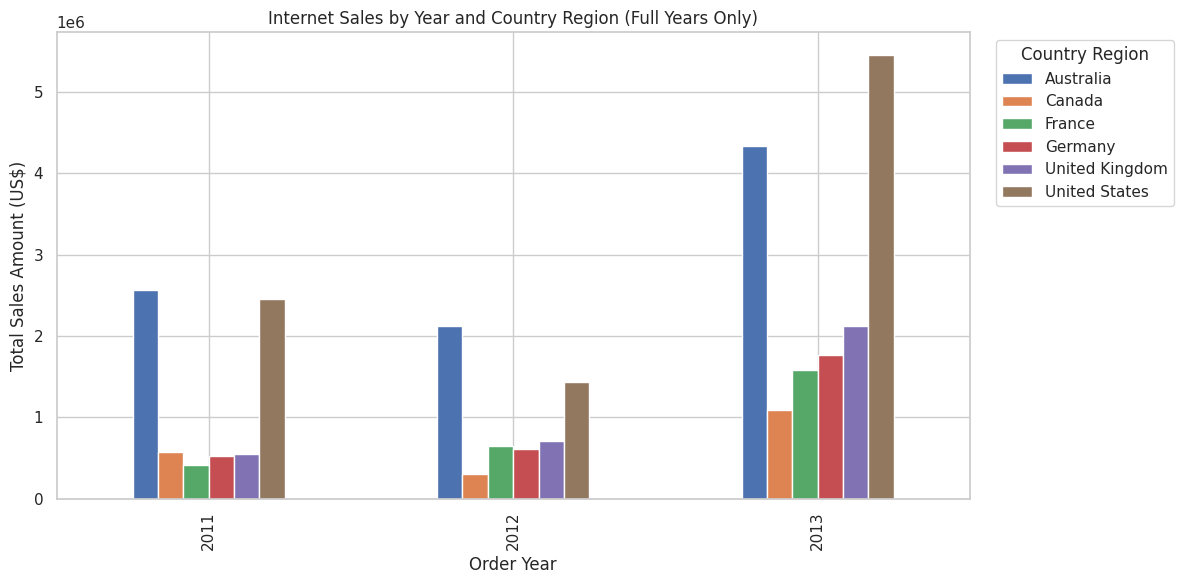

In [ ]:


# Q1. Internet Sales by Year and Country Region

# 1. Aggregate sales by year and country
year_country = (
    df.dropna(subset=['OrderYear', 'CountryRegion'])
      .groupby(['OrderYear', 'CountryRegion'])
      .agg(
          TotalSales=('SalesAmount', 'sum'),
          OrderLines=('ID', 'count'),
          Orders=('SalesOrderNumber', 'nunique'),
          Customers=('CustomerKey', 'nunique')
      )
      .reset_index()
      .sort_values(['OrderYear', 'CountryRegion'])
)

display(year_country)


# 2. Create pivot table
year_country_pivot = year_country.pivot_table(
    index='OrderYear',
    columns='CountryRegion',
    values='TotalSales',
    aggfunc='sum',
    fill_value=0
)

display(year_country_pivot)


# 3. Table 1: Sales by country and year (US$ Thousands)
table1 = year_country_pivot.T.copy()

table1['Total'] = table1.sum(axis=1)

table1.loc['Total'] = table1.sum(axis=0)

table1 = (table1 / 1000).round(1)

display(table1)


# 4. Figure 1: Sales by year and country (Full Years Only)
ax = year_country_pivot[
    year_country_pivot.index.isin([2011, 2012, 2013])
].plot(
    kind='bar',
    figsize=(12, 6)
)

ax.set_title('Internet Sales by Year and Country Region (Full Years Only)')
ax.set_xlabel('Order Year')
ax.set_ylabel('Total Sales Amount (US$)')
ax.legend(
    title='Country Region',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.tight_layout()
plt.savefig('fig1_sales_year_country.png', dpi=300, bbox_inches='tight')
plt.show()


Customers with inconsistent CountryRegion: 0
Customers with inconsistent Gender: 0
Customers with inconsistent YearlyIncome: 0
Customers with inconsistent HouseOwnerFlag: 0


,CountryRegion,Gender,Count,Min,Max,Mean,Median,Std
0,Australia,F,1777,10000,160000,65284.186832,70000.0,31164.355484
1,Australia,M,1814,10000,170000,63412.348401,70000.0,32450.714154
2,Canada,F,767,10000,170000,56505.867014,60000.0,19181.547228
3,Canada,M,804,10000,170000,57798.507463,60000.0,21214.769586
4,France,F,893,10000,110000,35341.545353,30000.0,26915.846864
5,France,M,917,10000,110000,36172.300981,30000.0,27633.454988
6,Germany,F,874,10000,130000,43810.068650,30000.0,35715.762070
7,Germany,M,906,10000,130000,42108.167770,30000.0,35277.485653
8,United Kingdom,F,934,10000,170000,52184.154176,30000.0,48288.436761
9,United Kingdom,M,979,10000,170000,52155.260470,30000.0,48593.219927


,CountryRegion,Count,Min,Max,Mean,Std
0,Australia,3591,0,1,0.505152,0.500043
1,Canada,1571,0,1,0.511776,0.500020
2,France,1810,0,1,0.506630,0.500094
3,Germany,1780,0,1,0.508989,0.500060
4,United Kingdom,1913,0,1,0.511762,0.499992
5,United States,7819,0,1,0.502750,0.500024


,CountryRegion,Gender,Customers,Sales,GenderPctWithinCountry
0,Australia,F,1777,4.634993e+06,49.484823
1,Australia,M,1814,4.426008e+06,50.515177
2,Canada,F,767,1.011320e+06,48.822406
3,Canada,M,804,9.665249e+05,51.177594
4,France,F,893,1.271964e+06,49.337017
5,France,M,917,1.372054e+06,50.662983
6,Germany,F,874,1.539713e+06,49.101124
7,Germany,M,906,1.354599e+06,50.898876
8,United Kingdom,F,934,1.615046e+06,48.823837
9,United Kingdom,M,979,1.776666e+06,51.176163


Gender,F,M
CountryRegion,,
Australia,1777,1814
Canada,767,804
France,893,917
Germany,874,906
United Kingdom,934,979
United States,3888,3931


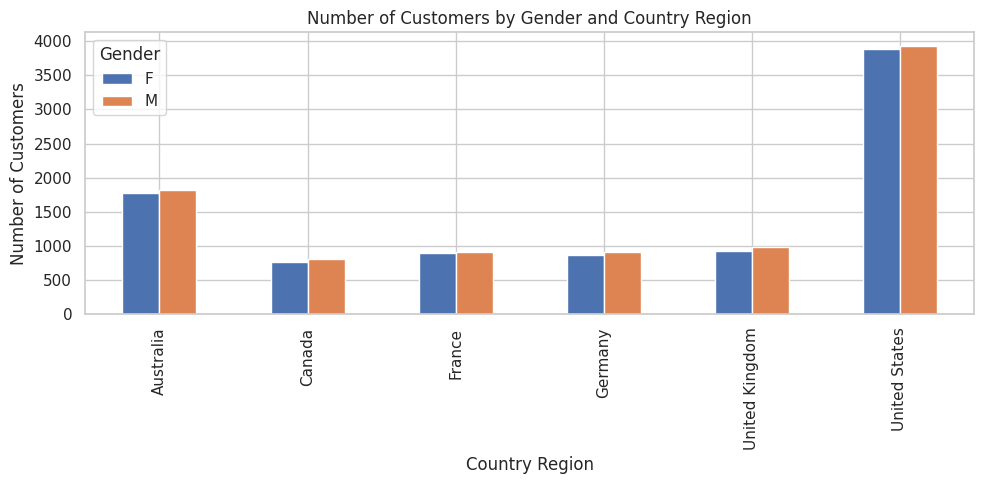

In [ ]:

# Check consistency of customer-level attributes
customer_attributes = [
    'CountryRegion',
    'Gender',
    'YearlyIncome',
    'HouseOwnerFlag'
]

for col in customer_attributes:
    check = df.groupby('CustomerKey')[col].nunique(dropna=False)

    print(
        f"Customers with inconsistent {col}:",
        (check > 1).sum()
    )

    assert (check <= 1).all(), (
        f"Inconsistent {col} values found!"
    )

# Create one row per customer
cust_df = df.drop_duplicates('CustomerKey').copy()




# 4.1 Yearly income statistics by country and gender
income_stats_country_gender = (
    cust_df.groupby(['CountryRegion', 'Gender'])['YearlyIncome']
      .agg(
          Count='count',
          Min='min',
          Max='max',
          Mean='mean',
          Median='median',
          Std='std'
      )
      .reset_index()
)

display(income_stats_country_gender)


# 4.2 Gender numeric statistics by country
gender_numeric_stats = (
    cust_df.groupby('CountryRegion')['GenderNumeric']
      .agg(
          Count='count',
          Min='min',
          Max='max',
          Mean='mean',
          Std='std'
      )
      .reset_index()
)

display(gender_numeric_stats)


# 4.3 Customer distribution by gender and country
gender_dist = (
    cust_df.groupby(['CountryRegion', 'Gender'])
      .agg(
          Customers=('CustomerKey', 'nunique')
      )
      .reset_index()
)

# Calculate actual sales using all transaction records
gender_sales = (
    df.groupby(['CountryRegion', 'Gender'])
      .agg(
          Sales=('SalesAmount', 'sum')
      )
      .reset_index()
)

# Merge customer counts and actual sales
gender_dist = gender_dist.merge(
    gender_sales,
    on=['CountryRegion', 'Gender'],
    validate='one_to_one'
)

# Gender percentage within each country
gender_dist['GenderPctWithinCountry'] = (
    gender_dist['Customers']
    / gender_dist.groupby('CountryRegion')['Customers']
      .transform('sum')
    * 100
)

display(gender_dist)


# Gender frequency pivot table
gender_pivot = gender_dist.pivot_table(
    index='CountryRegion',
    columns='Gender',
    values='Customers',
    aggfunc='sum',
    fill_value=0
)

display(gender_pivot)


# Figure 2
ax = gender_pivot.plot(
    kind='bar',
    figsize=(10, 5)
)

ax.set_title('Number of Customers by Gender and Country Region')
ax.set_xlabel('Country Region')
ax.set_ylabel('Number of Customers')

plt.tight_layout()
plt.savefig('fig2_gender_country.png', dpi=300, bbox_inches='tight')
plt.show()



,TotalSales,OrderLines,TotalQuantity,AvgUnitPrice,MedianUnitPrice,WeightedAvgPrice
ProductCategory,,,,,,
Bikes,2.831814e+07,15205,15205,1862.423193,2071.4196,1862.423193
Accessories,7.007600e+05,36092,36092,19.415936,9.9900,19.415936
Clothing,3.397726e+05,9101,9101,37.333547,49.9900,37.333547


Top product category by total sales: Bikes
Unweighted average unit price for top category: 1862.4231930746462
Weighted average selling price for top category: 1862.4231930746462


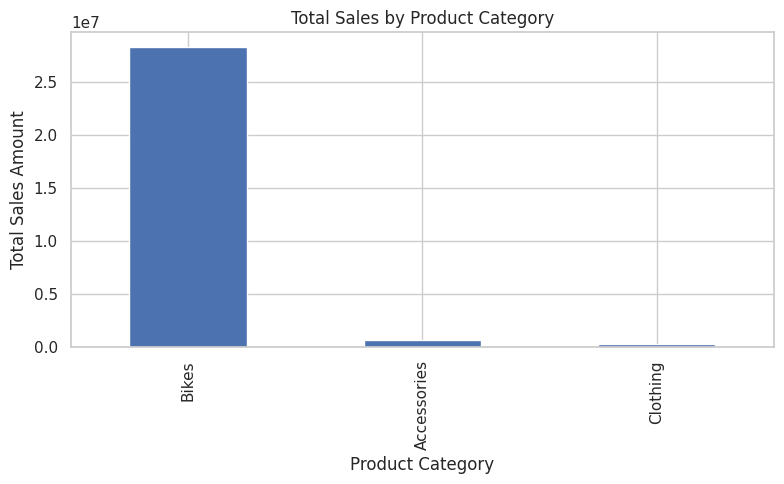

In [ ]:
category_summary = (
    df.groupby('ProductCategory')
      .agg(
          TotalSales=('SalesAmount', 'sum'),
          OrderLines=('ID', 'count'),
          TotalQuantity=('OrderQuantity', 'sum'),
          AvgUnitPrice=('UnitPrice', 'mean'),
          MedianUnitPrice=('UnitPrice', 'median')
      )
      .sort_values('TotalSales', ascending=False)
)


weighted_price = (
    df.groupby('ProductCategory')['SalesAmount'].sum()
    / df.groupby('ProductCategory')['OrderQuantity'].sum()
)

category_summary['WeightedAvgPrice'] = weighted_price
category_summary = category_summary.sort_values('TotalSales', ascending=False)

display(category_summary)

top_category = category_summary.index[0]
top_rows = df[df['ProductCategory'] == top_category]

avg_price_top_unweighted = top_rows['UnitPrice'].mean()
avg_price_top_weighted = top_rows['SalesAmount'].sum() / top_rows['OrderQuantity'].sum()

print("Top product category by total sales:", top_category)
print("Unweighted average unit price for top category:", avg_price_top_unweighted)
print("Weighted average selling price for top category:", avg_price_top_weighted)

# figure 3
ax = category_summary['TotalSales'].plot(kind='bar', figsize=(8, 5))
ax.set_title('Total Sales by Product Category')
ax.set_xlabel('Product Category')
ax.set_ylabel('Total Sales Amount')
plt.tight_layout()
plt.savefig('fig3_category_sales.png', dpi=300, bbox_inches='tight')
plt.show()

,HouseOwnerFlag,LineCount,TotalSales,MeanLineSales,MedianLineSales,StdLineSales
0,0,18699,8.973327e+06,479.882744,29.99,924.841795
1,1,41699,2.038535e+07,488.869033,32.60,930.118780


,HouseOwnerFlag,CustomerCount,TotalSales,MeanCustomerSales,MedianCustomerSales,StdCustomerSales
0,0,5982,8.973327e+06,1500.054735,209.96,2046.878581
1,1,12502,2.038535e+07,1630.567093,342.00,2159.068509


,HouseOwnerFlag,OrderCount,TotalSales,MeanOrderSales,MedianOrderSales,StdOrderSales
0,0,8601,8.973327e+06,1043.288853,574.98,1147.231126
1,1,19058,2.038535e+07,1069.647906,603.49,1149.771238


Customer-level Welch t-test:
TtestResult(statistic=np.float64(3.983828067367014), pvalue=np.float64(6.820263286221625e-05), df=np.float64(12367.36106833277))

Customer-level Mann-Whitney U test:
MannwhitneyuResult(statistic=np.float64(38559878.5), pvalue=np.float64(0.0005891308617497195))

Cohen's d for customer-level difference:
0.06146353140922165


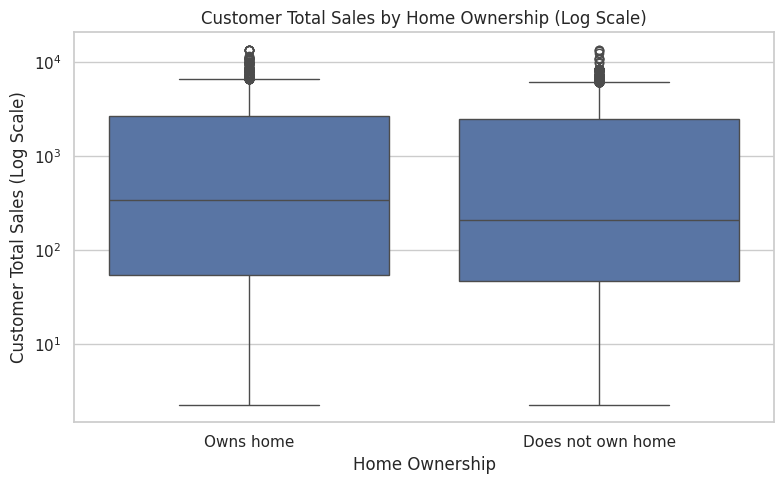

In [ ]:

# 6.1
house_line = (
    df.groupby('HouseOwnerFlag')['SalesAmount']
      .agg(
          LineCount='count',
          TotalSales='sum',
          MeanLineSales='mean',
          MedianLineSales='median',
          StdLineSales='std'
      )
      .reset_index()
)

display(house_line)

# 6.2
cust = (
    df.groupby('CustomerKey')
      .agg(
          HouseOwnerFlag=('HouseOwnerFlag', 'max'),
          TotalSales=('SalesAmount', 'sum'),
          OrderLines=('ID', 'count'),
          Orders=('SalesOrderNumber', 'nunique'),
          CountryRegion=('CountryRegion', 'first'),
          YearlyIncome=('YearlyIncome', 'first'),
          Gender=('Gender', 'first')
      )
      .reset_index()
)

house_cust = (
    cust.groupby('HouseOwnerFlag')['TotalSales']
        .agg(
            CustomerCount='count',
            TotalSales='sum',
            MeanCustomerSales='mean',
            MedianCustomerSales='median',
            StdCustomerSales='std'
        )
        .reset_index()
)

display(house_cust)

# 6.3
orders = (
    df.groupby(['CustomerKey', 'SalesOrderNumber'])
      .agg(
          HouseOwnerFlag=('HouseOwnerFlag', 'max'),
          OrderSales=('SalesAmount', 'sum'),
          CountryRegion=('CountryRegion', 'first')
      )
      .reset_index()
)

house_order = (
    orders.groupby('HouseOwnerFlag')['OrderSales']
          .agg(
              OrderCount='count',
              TotalSales='sum',
              MeanOrderSales='mean',
              MedianOrderSales='median',
              StdOrderSales='std'
          )
          .reset_index()
)

display(house_order)

# 6.4
owners_cust = cust.loc[cust['HouseOwnerFlag'] == 1, 'TotalSales'].dropna()
nonowners_cust = cust.loc[cust['HouseOwnerFlag'] == 0, 'TotalSales'].dropna()

print("Customer-level Welch t-test:")
print(stats.ttest_ind(owners_cust, nonowners_cust, equal_var=False))

print("\nCustomer-level Mann-Whitney U test:")
print(stats.mannwhitneyu(owners_cust, nonowners_cust, alternative='two-sided'))

# Cohen's d
def cohen_d(x, y):
    nx, ny = len(x), len(y)
    dof = nx + ny - 2
    pooled_std = np.sqrt(
        ((nx - 1) * np.var(x, ddof=1) + (ny - 1) * np.var(y, ddof=1)) / dof
    )
    if pooled_std == 0:
        return np.nan
    return (np.mean(x) - np.mean(y)) / pooled_std

print("\nCohen's d for customer-level difference:")
print(cohen_d(owners_cust, nonowners_cust))

# 6.5 figure 4
plot_df = cust.copy()
plot_df['OwnerLabel'] = plot_df['HouseOwnerFlag'].map({
    1: 'Owns home',
    0: 'Does not own home'
})

plt.figure(figsize=(8, 5))
sns.boxplot(data=plot_df, x='OwnerLabel', y='TotalSales')
plt.yscale('log')
plt.title('Customer Total Sales by Home Ownership (Log Scale)')
plt.xlabel('Home Ownership')
plt.ylabel('Customer Total Sales (Log Scale)')
plt.tight_layout()
plt.savefig('fig4_home_ownership.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
year_country.to_csv('q1_year_country_sales.csv', index=False)
year_country_pivot.to_csv('q1_year_country_sales_pivot.csv')

income_stats_country_gender.to_csv(
    'q2_income_stats_by_country_gender.csv', index=False
)
gender_numeric_stats.to_csv(
    'q2_gender_numeric_stats_by_country.csv', index=False
)
gender_dist.to_csv(
    'q2_gender_distribution_by_country.csv', index=False
)

category_summary.to_csv('q3_category_summary.csv')

house_line.to_csv('q4_house_line_level.csv', index=False)
house_cust.to_csv('q4_house_customer_level.csv', index=False)
house_order.to_csv('q4_house_order_level.csv', index=False)


with pd.ExcelWriter('assignment2_output_tables.xlsx') as writer:
    year_country.to_excel(writer, sheet_name='Q1_year_country', index=False)
    year_country_pivot.to_excel(writer, sheet_name='Q1_pivot')
    income_stats_country_gender.to_excel(
        writer, sheet_name='Q2_income_gender', index=False
    )
    gender_numeric_stats.to_excel(
        writer, sheet_name='Q2_gender_numeric', index=False
    )
    gender_dist.to_excel(writer, sheet_name='Q2_gender_dist', index=False)
    category_summary.to_excel(writer, sheet_name='Q3_category')
    house_line.to_excel(writer, sheet_name='Q4_line', index=False)
    house_cust.to_excel(writer, sheet_name='Q4_customer', index=False)
    house_order.to_excel(writer, sheet_name='Q4_order', index=False)

print("Tables exported.")

Tables exported.


In [ ]:


# ===== Supplemental analysis for the recommendation =====

total_sales = df['SalesAmount'].sum()

# S1. Sales by product category and year
cat_year = df.pivot_table(
    index='ProductCategory',
    columns='OrderYear',
    values='SalesAmount',
    aggfunc='sum',
    fill_value=0
)

display(cat_year.round(0))


# S2. Gross margin and sales share by category
margin = df.groupby('ProductCategory').agg(
    Sales=('SalesAmount', 'sum'),
    Cost=('TotalProductCost', 'sum')
)

margin['GrossMarginPct'] = (
    (margin['Sales'] - margin['Cost']) / margin['Sales'] * 100
)

margin['SalesSharePct'] = (
    margin['Sales'] / total_sales * 100
)

display(margin.round(1))

overall_margin = (
    (total_sales - df['TotalProductCost'].sum()) / total_sales
)

print('Overall gross margin (%):', round(overall_margin * 100, 1))


# S3. Country sales share and sales per customer
ctry = df.groupby('CountryRegion').agg(
    Sales=('SalesAmount', 'sum'),
    Customers=('CustomerKey', 'nunique')
)

ctry['SalesSharePct'] = ctry['Sales'] / total_sales * 100
ctry['SalesPerCustomer'] = ctry['Sales'] / ctry['Customers']

ctry = ctry.sort_values('Sales', ascending=False)

display(ctry.round(2))



# S4. Bike orders with and without add-on products
order_summary = df.groupby('SalesOrderNumber').agg(
    Sales=('SalesAmount', 'sum'),
    OrderYear=('OrderYear', 'first'),
    CustomerKey=('CustomerKey', 'first'),
    HasBike=('ProductCategory', lambda x: (x == 'Bikes').any()),
    HasAddOn=('ProductCategory', lambda x: (x != 'Bikes').any())
).reset_index()

bike13 = order_summary[
    (order_summary['OrderYear'] == 2013) &
    (order_summary['HasBike'])
].copy()

bike_only_orders = int((~bike13['HasAddOn']).sum())
bike_addon_orders = int(bike13['HasAddOn'].sum())

bike_only_aov = bike13.loc[
    ~bike13['HasAddOn'], 'Sales'
].mean()

bike_addon_aov = bike13.loc[
    bike13['HasAddOn'], 'Sales'
].mean()

print('2013 bike-only orders:', bike_only_orders)
print('2013 bike orders with add-ons:', bike_addon_orders)
print('Average bike-only order value ($):', round(bike_only_aov, 2))
print('Average bike-plus-add-on order value ($):', round(bike_addon_aov, 2))
print('Observed order-value difference ($):',
      round(bike_addon_aov - bike_only_aov, 2))

# Note: The order-value difference is descriptive.
# It should not be treated as guaranteed incremental add-on revenue.


# S5. European customer growth scenario
# Use 2013 as the full-year baseline

eu = [
    'United Kingdom',
    'Germany',
    'France'
]

eu_2013 = df[
    (df['OrderYear'] == 2013) &
    (df['CountryRegion'].isin(eu))
].copy()

eu_sales_2013 = eu_2013['SalesAmount'].sum()

eu_customers_2013 = eu_2013['CustomerKey'].nunique()

eu_avg_sales_per_customer_2013 = (
    eu_sales_2013 / eu_customers_2013
)

# Assume a 10% increase in active customers
new_customers_scenario = eu_customers_2013 * 0.10

scenario_eu_sales = (
    new_customers_scenario *
    eu_avg_sales_per_customer_2013
)

# Calculate European gross margin using 2013 data
eu_cost_2013 = eu_2013['TotalProductCost'].sum()

eu_margin_2013 = (
    (eu_sales_2013 - eu_cost_2013) / eu_sales_2013
)

scenario_eu_gross_profit = (
    scenario_eu_sales * eu_margin_2013
)

print('2013 European sales ($):', round(eu_sales_2013, 2))
print('2013 European active customers:', eu_customers_2013)
print('Average sales per active customer ($):',
      round(eu_avg_sales_per_customer_2013, 2))
print('Assumed additional customers:', round(new_customers_scenario))
print('10% customer growth scenario sales ($):',
      round(scenario_eu_sales, 2))
print('Estimated gross profit ($):',
      round(scenario_eu_gross_profit, 2))




OrderYear,2010,2011,2012,2013,2014
ProductCategory,,,,,
Accessories,0.0,0.0,2147.0,668242.0,30371.0
Bikes,43421.0,7075526.0,5839695.0,15359502.0,0.0
Clothing,0.0,0.0,643.0,323806.0,15323.0


,Sales,Cost,GrossMarginPct,SalesSharePct
ProductCategory,,,,
Accessories,700760.0,262085.4,62.6,2.4
Bikes,28318144.7,16812348.2,40.6,96.5
Clothing,339772.6,203360.0,40.1,1.2


Overall gross margin (%): 41.1


,Sales,Customers,SalesSharePct,SalesPerCustomer
CountryRegion,,,,
United States,9389789.51,7819,31.98,1200.89
Australia,9061000.58,3591,30.86,2523.25
United Kingdom,3391712.21,1913,11.55,1772.98
Germany,2894312.34,1780,9.86,1626.02
France,2644017.71,1810,9.01,1460.78
Canada,1977844.86,1571,6.74,1258.97


2013 bike-only orders: 1205
2013 bike orders with add-ons: 8501
Average bike-only order value ($): 1533.47
Average bike-plus-add-on order value ($): 1637.09
Observed order-value difference ($): 103.63
2013 European sales ($): 5464395.45
2013 European active customers: 5265
Average sales per active customer ($): 1037.87
Assumed additional customers: 526
10% customer growth scenario sales ($): 546439.54
Estimated gross profit ($): 225502.43


In [ ]:
# ===== Evidence cell: prints every figure cited in the report that is not shown above =====

# E1. Data coverage by year
display(df.groupby('OrderYear')['OrderDate'].agg(['min', 'max', 'count']))
print('Bike sales in 2014 ($):',
      df.loc[(df['OrderYear'] == 2014) & (df['ProductCategory'] == 'Bikes'), 'SalesAmount'].sum())

# E2. Growth by country and Europe's share of 2013 sales
growth = pd.DataFrame({
    'Change_2011_2012_Pct': (year_country_pivot.loc[2012] / year_country_pivot.loc[2011] - 1) * 100,
    'Growth_2011_2013_Pct': (year_country_pivot.loc[2013] / year_country_pivot.loc[2011] - 1) * 100
}).round(1)
display(growth.sort_values('Growth_2011_2013_Pct', ascending=False))

eu = ['United Kingdom', 'Germany', 'France']
print('Europe share of 2013 sales (%):',
      round(year_country_pivot.loc[2013, eu].sum() / year_country_pivot.loc[2013].sum() * 100, 1))
print('2013 share of all sales (%):',
      round(year_country_pivot.loc[2013].sum() / year_country_pivot.values.sum() * 100, 1))

# E3. Data checks
print('Rows with a discount:', int((df['UnitPriceDiscountPct'] != 0).sum()),
      '| duplicated rows:', int(df.duplicated().sum()))
print('Distinct yearly income values:', sorted(df['YearlyIncome'].unique().tolist()))

# E4. Home ownership context
print('Mean yearly income by home ownership ($):')
display(cust.groupby('HouseOwnerFlag')['YearlyIncome'].mean().round(0))

# E5. Add-on orders, repeat buying, monthly sales
addon_rev = (df[(df['OrderYear'] == 2013) & (df['ProductCategory'] != 'Bikes')]
             .groupby('SalesOrderNumber')['SalesAmount'].sum())
bike13_addon = bike13[bike13['HasAddOn']].copy()
bike13_addon['AddOnRevenue'] = bike13_addon['SalesOrderNumber'].map(addon_rev)

print('Share of 2013 bike orders with an add-on (%):',
      round(bike_addon_orders / (bike_addon_orders + bike_only_orders) * 100, 1))
print('Average add-on revenue inside a bike order with add-ons ($):',
      round(bike13_addon['AddOnRevenue'].mean(), 2))

orders_per_customer = df.groupby('CustomerKey')['SalesOrderNumber'].nunique()
print('Customers with 2+ orders (%):', round((orders_per_customer > 1).mean() * 100, 1))

d13 = df[df['OrderYear'] == 2013]
monthly_2013 = d13.pivot_table(index=d13['OrderDate'].dt.month, columns='ProductCategory',
                               values='SalesAmount', aggfunc='sum', fill_value=0)
monthly_2013['Total'] = monthly_2013.sum(axis=1)
display(monthly_2013.round(0))

# E6. Scenario compared with the 2013 baseline (same year as the scenario)
print('Scenario sales as % of 2013 total sales:',
      round(scenario_eu_sales / year_country_pivot.loc[2013].sum() * 100, 1), '%')

,min,max,count
OrderYear,,,
2010,2010-12-29,2010-12-31,14
2011,2011-01-01,2011-12-31,2216
2012,2012-01-01,2012-12-31,3397
2013,2013-01-01,2013-12-31,52801
2014,2014-01-01,2014-01-28,1970


Bike sales in 2014 ($): 0.0


,Change_2011_2012_Pct,Growth_2011_2013_Pct
CountryRegion,,
United Kingdom,29.4,285.8
France,57.7,284.2
Germany,16.9,238.5
United States,-41.5,122.2
Canada,-46.2,89.9
Australia,-17.0,69.3


Europe share of 2013 sales (%): 33.4
2013 share of all sales (%): 55.7
Rows with a discount: 0 | duplicated rows: 0
Distinct yearly income values: [10000, 20000, 30000, 40000, 50000, 60000, 70000, 80000, 90000, 100000, 110000, 120000, 130000, 150000, 160000, 170000]
Mean yearly income by home ownership ($):


,YearlyIncome
HouseOwnerFlag,
0,55172.0
1,58327.0


Share of 2013 bike orders with an add-on (%): 87.6
Average add-on revenue inside a bike order with add-ons ($): 47.67
Customers with 2+ orders (%): 37.1


ProductCategory,Accessories,Bikes,Clothing,Total
OrderDate,,,,
1,19050.0,829911.0,8729.0,857690.0
2,46246.0,703797.0,21306.0,771349.0
3,55339.0,967773.0,26795.0,1049907.0
4,51722.0,968904.0,25397.0,1046023.0
5,57877.0,1200153.0,26563.0,1284593.0
6,62527.0,1551225.0,29425.0,1643178.0
7,58002.0,1284187.0,29487.0,1371676.0
8,59737.0,1461493.0,29835.0,1551066.0
9,58523.0,1361345.0,27628.0,1447496.0


Scenario sales as % of 2013 total sales: 3.3 %


In [ ]:
# ===== Optional: does the home ownership gap survive adjustment? =====
import statsmodels.formula.api as smf

reg = cust.copy()
first_year = df.groupby('CustomerKey')['DateFirstPurchase'].first().dt.year
reg['FirstPurchaseYear'] = reg['CustomerKey'].map(first_year)

model = smf.ols(
    'TotalSales ~ HouseOwnerFlag + C(CountryRegion) + C(FirstPurchaseYear) + YearlyIncome',
    data=reg
).fit(cov_type='HC3')

ci = model.conf_int().loc['HouseOwnerFlag']
print('Unadjusted gap ($):', round(owners_cust.mean() - nonowners_cust.mean(), 2))
print('Adjusted homeowner coefficient ($):', round(model.params['HouseOwnerFlag'], 2))
print('95% CI ($):', round(ci[0], 1), 'to', round(ci[1], 1))

Unadjusted gap ($): 130.51
Adjusted homeowner coefficient ($): 55.82
95% CI ($): 22.3 to 89.3
